# 09 — Random Forest

> Many deliberately different decision trees, voting together — and beating any one of them.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. The data
5. Modeling
6. Results and interpretation
7. References

## 1. The problem

A biopsy sample is photographed under a microscope, and software measures the
cell nuclei it can see: how large they are, how irregular their outline is, how
much their size varies within the sample. The question is whether the tissue is
**malignant** or **benign**.

- **Inputs:** 30 numeric measurements per patient
- **Output:** one of two labels, malignant or benign
- **A good answer** classifies patients the model has never seen, and — because
  of what is being predicted — misses as few malignant cases as possible.

Lesson 06 ended on an unresolved weakness. A single decision tree grown until
its leaves are pure fits its training data perfectly, and *"a single tree can
change a lot when a few training rows change. Ensembles of trees, such as random
forests, exist to fix that."*

This lesson takes that sentence and measures it.

## 2. Intuition

Ask one specialist for a diagnosis and you get one opinion, shaped by the cases
that specialist happens to have seen. Ask a hundred and take the majority view,
and the individual quirks cancel out.

That only works under one condition: **the specialists must not all be the
same**. A hundred identical opinions is still one opinion. The committee is
useful precisely because its members disagree, and the disagreements are what
average away.

A random forest manufactures that disagreement deliberately, in two ways:

- **Each tree sees a different sample of the patients.** Rows are drawn at
  random *with replacement*, so one tree may see a patient twice and another not
  at all.
- **Each tree is allowed to consider only a random handful of the measurements
  when choosing a split.** Without this, every tree would seize on the same
  strongest feature first and they would all end up nearly identical.

Then every tree votes, and the majority wins.

The surprising part is that making each individual tree *worse* — starving it of
rows and of features — makes the group *better*. Section 5 shows this happening.

## 3. The mathematics

**What a single tree does wrong.** Lesson 06 showed a tree splitting to reduce
entropy until its leaves are pure. Nothing stops it from carving out a branch to
accommodate a single unusual patient. That branch fits the training set and
describes nobody else.

Prediction error can be split into three parts:

$$
\text{error} = \underbrace{\text{bias}^2}_{\text{too simple to be right}} + \underbrace{\text{variance}}_{\text{too sensitive to this particular data}} + \underbrace{\text{noise}}_{\text{irreducible}}
$$

A fully grown tree has **low bias** — it can represent almost any rule — and
**high variance**: change a few training rows and the tree changes shape.

**Why averaging helps.** Take $B$ predictors, each with variance $\sigma^2$, and
average them. If they were perfectly independent, the average would have
variance

$$
\frac{\sigma^2}{B}
$$

More realistically they are correlated with one another by some amount $\rho$,
and the variance of the average is

$$
\rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2
$$

Read that second formula carefully, because the whole method is in it:

- Adding trees ($B \to \infty$) drives the second term to zero. More trees never
  hurt — they just stop helping.
- The first term, $\rho \sigma^2$, does **not** shrink with more trees. It is
  floored by how *correlated* the trees are. The only way to lower it is to make
  the trees more different from each other.

That is exactly why the feature subsetting exists. Bootstrapping alone leaves
trees that still agree too often; forcing each split to choose among a random
subset of features drives $\rho$ down.

**Bias is untouched.** Averaging reduces variance, not bias. This is why the
trees in a forest are grown deep rather than pruned: each one should be low-bias
and high-variance, and the averaging is what deals with the variance.

**The two settings that follow from this:**

- $B$ = `n_estimators`, the number of trees. More is better until it plateaus.
- $m$ = `max_features`, how many features each split may consider. The usual
  default for classification is $m = \sqrt{p}$, which here is
  $\sqrt{30} \approx 5$.

## 4. The data

The Wisconsin Diagnostic Breast Cancer dataset: 569 biopsies, each described by
30 measurements computed from a digitised image of the cell nuclei.

The measurements come in three groups of ten — the **mean**, the **standard
error**, and the **worst** (largest) value observed for each of ten properties:
radius, texture, perimeter, area, smoothness, compactness, concavity, concave
points, symmetry, and fractal dimension.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Fixed seed so the split, the trees and every number below are identical on
# every run.
RANDOM_SEED = 42

In [2]:
df = pd.read_csv("data/breast_cancer.csv")

print("shape:", df.shape)
print("missing values:", df.isnull().sum().sum())
df.head()

shape: (569, 31)
missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# 0 = malignant, 1 = benign
counts = df["diagnosis"].value_counts().rename({0: "malignant", 1: "benign"})
print(counts.to_string())
print(f"\nbenign share: {counts['benign'] / len(df):.3f}")

diagnosis
benign       357
malignant    212

benign share: 0.627


Roughly 63% benign. That number is the score to beat: a model that ignores every
measurement and always answers "benign" is right 63% of the time, so any accuracy
near that figure means nothing has been learned.

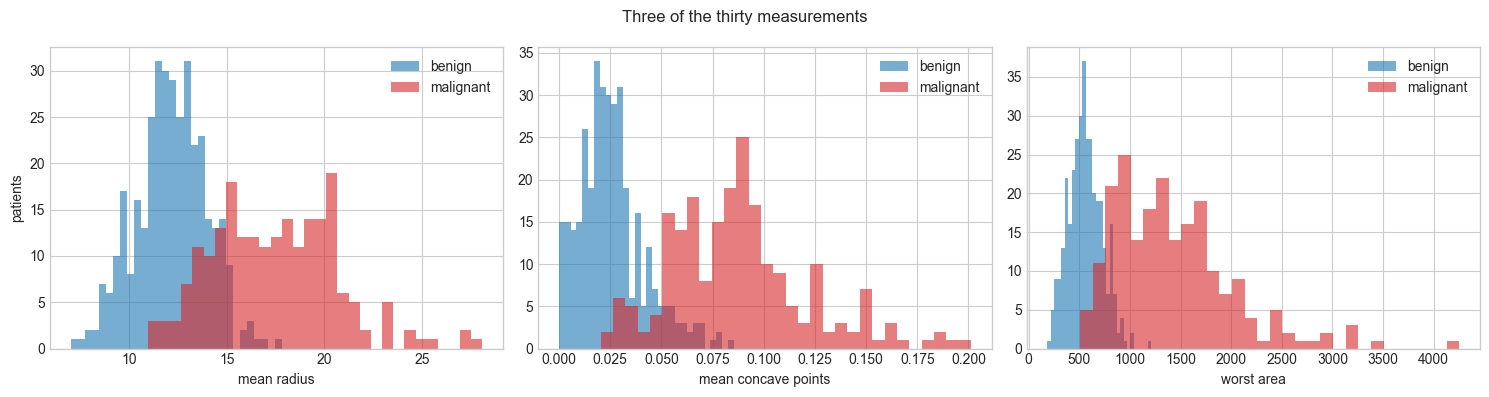

In [4]:
# A first look: do the measurements separate the two groups at all?
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["mean radius", "mean concave points", "worst area"]):
    for label, name, colour in [(1, "benign", "tab:blue"), (0, "malignant", "tab:red")]:
        ax.hist(df.loc[df["diagnosis"] == label, col], bins=30, alpha=0.6, label=name, color=colour)
    ax.set_xlabel(col)
    ax.legend()

axes[0].set_ylabel("patients")
fig.suptitle("Three of the thirty measurements")
plt.tight_layout()
plt.show()

The two groups overlap but are clearly shifted apart: malignant samples tend to
have larger, more irregular nuclei. No single measurement separates them
cleanly, which is what makes this a modelling problem rather than a lookup.

### Creating train and test datasets

`stratify=y` keeps the same malignant/benign proportion in both halves. Without
it, a random split can hand the test set an unrepresentative mix and the score
becomes hard to read.

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

print("Train set:", X_train.shape, y_train.shape)
print("Test set: ", X_test.shape, y_test.shape)

baseline = y_test.mean()  # always predicting "benign"
print(f"\nBaseline - always answer 'benign': {baseline:.4f}")

Train set: (455, 30) (455,)
Test set:  (114, 30) (114,)

Baseline - always answer 'benign': 0.6316


No scaling this time. Trees split on one feature at a time by asking "is this
value above or below a threshold", and that question has the same answer whatever
units the feature is in. Lessons 05 and 07 needed `StandardScaler` because
distances and gradients care about scale; trees do not.

## 5. Modeling

### 5.1 One tree, to have something to beat

In [6]:
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=RANDOM_SEED)
tree.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree.predict(X_train))
test_acc = accuracy_score(y_test, tree.predict(X_test))

print(f"depth reached:  {tree.get_depth()}")
print(f"train accuracy: {train_acc:.4f}")
print(f"test accuracy:  {test_acc:.4f}")

depth reached:  7
train accuracy: 1.0000
test accuracy:  0.9123


**1.0000 on training data, 0.9123 on patients it has never seen.** The tree has
not learned 100% of anything — it has memorised 455 patients. The nine-point gap
between the two numbers is the variance from section 3, in one line of output.

### 5.2 How fragile is one tree?

If the problem really is variance, then re-running the *same* algorithm on the
*same* data, changing only the random tie-breaking, should move the answer
around. Here is that experiment.

In [7]:
tree_scores = []
for seed in range(15):
    t = DecisionTreeClassifier(random_state=seed).fit(X_train, y_train)
    tree_scores.append(accuracy_score(y_test, t.predict(X_test)))

tree_scores = np.array(tree_scores)
print("single tree, 15 different seeds")
print(f"  lowest:  {tree_scores.min():.4f}")
print(f"  highest: {tree_scores.max():.4f}")
print(f"  spread:  {tree_scores.max() - tree_scores.min():.4f}")

single tree, 15 different seeds
  lowest:  0.8947
  highest: 0.9211
  spread:  0.0263


Same data, same settings, nothing changed but a random seed — and the answer
moves by more than two and a half points. A model whose score depends on its
seed is telling you it is fitting accidents of the training set.

Section 6 runs the identical experiment on forests.

### 5.3 The concept: building a small forest by hand

Before reaching for the library, here is the whole idea in a dozen lines:

1. draw a **bootstrap sample** — as many rows as the training set, chosen at
   random *with replacement*
2. pick a **random subset of the features**
3. grow one unrestricted tree on that
4. repeat, then let the trees **vote**

In [8]:
rng = np.random.default_rng(RANDOM_SEED)

n_trees = 50
n_features = int(np.sqrt(X.shape[1]))  # 5 of the 30 measurements

predictions = []
for _ in range(n_trees):
    # 1. bootstrap the rows: same number, drawn with replacement
    row_idx = rng.integers(0, len(X_train), len(X_train))

    # 2. a random handful of the measurements
    cols = rng.choice(X.columns, size=n_features, replace=False)

    # 3. one deep tree on that deliberately partial view
    stump = DecisionTreeClassifier(random_state=RANDOM_SEED)
    stump.fit(X_train.iloc[row_idx][cols], y_train.iloc[row_idx])

    predictions.append(stump.predict(X_test[cols]))

predictions = np.array(predictions)  # shape: (n_trees, n_test_patients)

# 4. the vote: average the 0/1 predictions, then round
majority = (predictions.mean(axis=0) >= 0.5).astype(int)

print(f"one tree on a partial view: {accuracy_score(y_test, predictions[0]):.4f}")
print(f"all {n_trees} trees voting:        {accuracy_score(y_test, majority):.4f}")

one tree on a partial view: 0.8947
all 50 trees voting:        0.9386


The first tree, handicapped with 5 features and a bootstrap sample, scores
*below* the full single tree from 5.1. Fifty such handicapped trees voting score
*above* it. That is the whole method in two numbers.

How quickly does the vote improve as trees are added?

In [9]:
for k in [1, 3, 5, 10, 25, 50]:
    vote_k = (predictions[:k].mean(axis=0) >= 0.5).astype(int)
    print(f"  first {k:2d} trees: {accuracy_score(y_test, vote_k):.4f}")

  first  1 trees: 0.8947
  first  3 trees: 0.9211
  first  5 trees: 0.9561
  first 10 trees: 0.9561
  first 25 trees: 0.9474
  first 50 trees: 0.9386


Most of the gain arrives within the first handful of trees, and after that the
numbers wobble by a point or so in both directions. With 114 test patients, one
patient is worth 0.9 points — so those late wobbles are noise, not a trend.

### 5.4 The same thing, with scikit-learn

`RandomForestClassifier` does what section 5.3 does, with one refinement that
matters: it draws a fresh random subset of features at **every split**, not once
per tree. Each tree therefore explores many different combinations instead of
being locked into five measurements for its whole depth.

In [10]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",   # 5 of 30 considered at each split
    oob_score=True,        # see 5.6
    random_state=RANDOM_SEED,
)
forest.fit(X_train, y_train)

print(f"hand-built forest (50 trees): {accuracy_score(y_test, majority):.4f}")
print(f"scikit-learn forest (100):    {accuracy_score(y_test, forest.predict(X_test)):.4f}")
print(f"single tree (5.1):            {test_acc:.4f}")

hand-built forest (50 trees): 0.9386
scikit-learn forest (100):    0.9561
single tree (5.1):            0.9123


The library version wins, and the reason is the refinement just described —
subsetting per split rather than per tree makes the trees differ in more ways,
which is the $\rho$ term from section 3 being pushed down.

The hand-built version is not wasted: it is the same algorithm, and it shows
that nothing mysterious is happening inside the library call.

### 5.5 How many trees are enough?

Section 3 predicted that accuracy rises with the number of trees and then
flattens, because the $\frac{1-\rho}{B}\sigma^2$ term shrinks while
$\rho \sigma^2$ does not.

In [11]:
sizes = [1, 2, 5, 10, 25, 50, 100, 200, 400]
curve = []

for n in sizes:
    f = RandomForestClassifier(n_estimators=n, max_features="sqrt", random_state=RANDOM_SEED)
    f.fit(X_train, y_train)
    curve.append(accuracy_score(y_test, f.predict(X_test)))

for n, acc in zip(sizes, curve):
    print(f"  {n:4d} trees: {acc:.4f}")

     1 trees: 0.9474
     2 trees: 0.9386
     5 trees: 0.9386
    10 trees: 0.9386
    25 trees: 0.9561
    50 trees: 0.9561
   100 trees: 0.9561
   200 trees: 0.9561
   400 trees: 0.9561


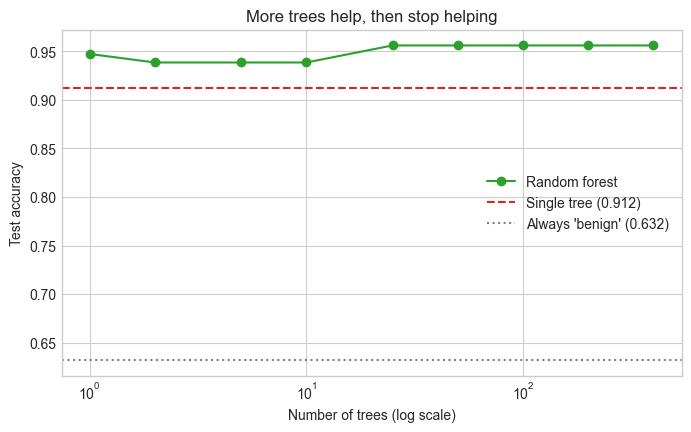

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sizes, curve, marker="o", color="tab:green", label="Random forest")
ax.axhline(test_acc, color="tab:red", linestyle="--", label=f"Single tree ({test_acc:.3f})")
ax.axhline(baseline, color="grey", linestyle=":", label=f"Always 'benign' ({baseline:.3f})")
ax.set_xscale("log")
ax.set_xlabel("Number of trees (log scale)")
ax.set_ylabel("Test accuracy")
ax.set_title("More trees help, then stop helping")
ax.legend()
plt.savefig("figures/n_estimators.png", dpi=150, bbox_inches="tight")
plt.show()

The left-hand side of this curve is noise, and it is worth being honest about
that rather than describing a climb that is not there. With 114 test patients
each one is worth 0.9 points, and a one-tree "forest" happens to score 0.947
here — better than the runs with 2, 5 or 10 trees.

What is trustworthy is the right-hand side: from about 25 trees the score settles
at 0.956 and does not move again, whatever is added after. That flat stretch is
the plateau section 3 predicted, where $\frac{1-\rho}{B}\sigma^2$ has gone to
zero and only $\rho\sigma^2$ is left.

The lesson is not that one tree is as good as twenty-five. Section 5.2 already
showed a single tree swinging 2.6 points depending on its seed — that 0.947 is
one lucky draw, not a reliable result. The point is that a score means little
until the forest is large enough to stop moving, and that adding trees past the
plateau costs time without ever making things worse.

### 5.6 A free validation score

Each tree is trained on a bootstrap sample, so about a third of the patients are
left out of any given tree. Those are its **out-of-bag** patients: unseen by that
tree, and therefore usable to score it. Averaging over all trees gives a
validation estimate without holding anything back.

In [13]:
print(f"out-of-bag score: {forest.oob_score_:.4f}")
print(f"test accuracy:    {accuracy_score(y_test, forest.predict(X_test)):.4f}")

# The share of patients left out of a given tree settles near 1/e.
print(f"\nexpected share left out of each tree: {1 / np.e:.3f}")

out-of-bag score: 0.9538
test accuracy:    0.9561

expected share left out of each tree: 0.368


The out-of-bag estimate lands close to the test score, which is what makes it
useful: on a small dataset it lets you compare settings without spending test
data, and without the cost of a separate cross-validation run.

## 6. Results and interpretation

### Does the forest fix the fragility?

Section 5.2 found a single tree swinging 2.6 points across random seeds. The
same experiment, on forests:

In [14]:
forest_scores = []
for seed in range(15):
    f = RandomForestClassifier(n_estimators=100, max_features="sqrt", random_state=seed)
    f.fit(X_train, y_train)
    forest_scores.append(accuracy_score(y_test, f.predict(X_test)))

forest_scores = np.array(forest_scores)

print(f"single tree   - spread across 15 seeds: {tree_scores.max() - tree_scores.min():.4f}")
print(f"random forest - spread across 15 seeds: {forest_scores.max() - forest_scores.min():.4f}")
print(f"\nsingle tree   mean: {tree_scores.mean():.4f}")
print(f"random forest mean: {forest_scores.mean():.4f}")

single tree   - spread across 15 seeds: 0.0263
random forest - spread across 15 seeds: 0.0088

single tree   mean: 0.9094
random forest mean: 0.9544


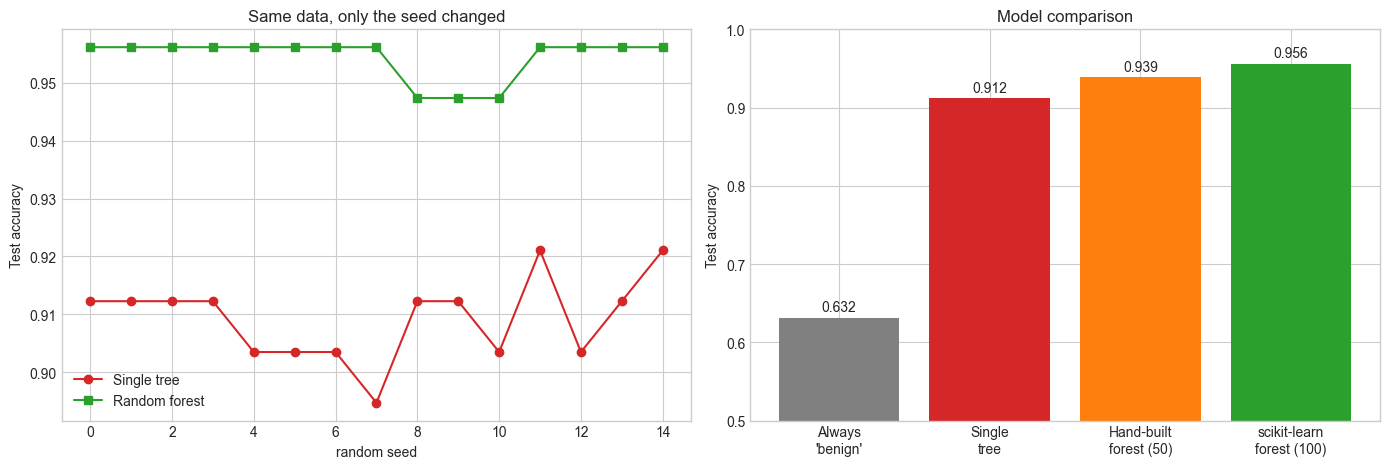

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Left: how much each model moves when only the seed changes
axes[0].plot(range(15), tree_scores, marker="o", label="Single tree", color="tab:red")
axes[0].plot(range(15), forest_scores, marker="s", label="Random forest", color="tab:green")
axes[0].set_xlabel("random seed")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Same data, only the seed changed")
axes[0].legend()

# Right: the headline comparison
names = ["Always\n'benign'", "Single\ntree", "Hand-built\nforest (50)", "scikit-learn\nforest (100)"]
values = [baseline, test_acc, accuracy_score(y_test, majority), accuracy_score(y_test, forest.predict(X_test))]
bars = axes[1].bar(names, values, color=["grey", "tab:red", "tab:orange", "tab:green"])
axes[1].set_ylim(0.5, 1.0)
axes[1].set_ylabel("Test accuracy")
axes[1].set_title("Model comparison")
for bar, v in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 0.008, f"{v:.3f}", ha="center")

plt.tight_layout()
# Saved so README.md can show the result without anyone running this notebook.
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

The forest line is visibly flatter. Its spread across seeds is about a third of
the tree's, and every one of its runs beats every one of the tree's. The forest
is not just better on average — it is **predictably** better, which is what lets
you trust a single run of it.

### Which measurements matter?

A forest can report how much each feature contributed, averaged over every split
in every tree.

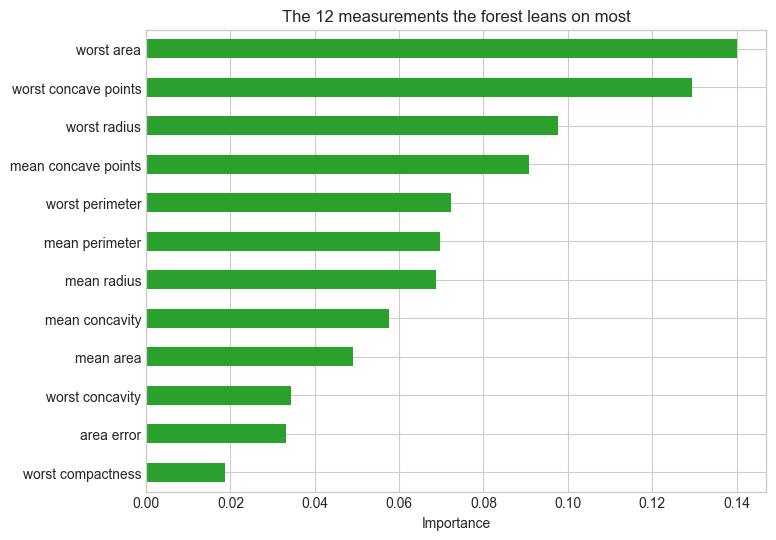

worst area              0.1400
worst concave points    0.1295
worst radius            0.0977
mean concave points     0.0909
worst perimeter         0.0722
mean perimeter          0.0696
mean radius             0.0687
mean concavity          0.0576

the 5 least useful features together: 0.0204


In [16]:
importances = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importances.head(12).iloc[::-1].plot.barh(ax=ax, color="tab:green")
ax.set_xlabel("Importance")
ax.set_title("The 12 measurements the forest leans on most")
plt.savefig("figures/importances.png", dpi=150, bbox_inches="tight")
plt.show()

print(importances.head(8).round(4).to_string())
print(f"\nthe 5 least useful features together: {importances.tail(5).sum():.4f}")

The top of the list is dominated by **size and shape irregularity** — `worst
area`, `worst concave points`, `worst radius` — and the "worst" variants outrank
their "mean" counterparts. That is clinically sensible: what matters is the most
abnormal nucleus in the sample, not the average one.

Two cautions on reading this chart:

- Several of these measurements are near-duplicates of each other. `worst area`,
  `worst radius` and `worst perimeter` describe the same thing. The forest
  spreads importance across them, so a feature can look unimportant simply
  because a twin absorbed the credit.
- Importance measures **use**, not **cause**. It says the forest found a feature
  useful for splitting, not that the property drives the diagnosis.

### Reading the errors

With a medical question, overall accuracy is the least interesting number. The
two kinds of mistake are not equivalent.

              precision    recall  f1-score   support

   malignant      0.951     0.929     0.940        42
      benign      0.959     0.972     0.966        72

    accuracy                          0.956       114
   macro avg      0.955     0.950     0.953       114
weighted avg      0.956     0.956     0.956       114



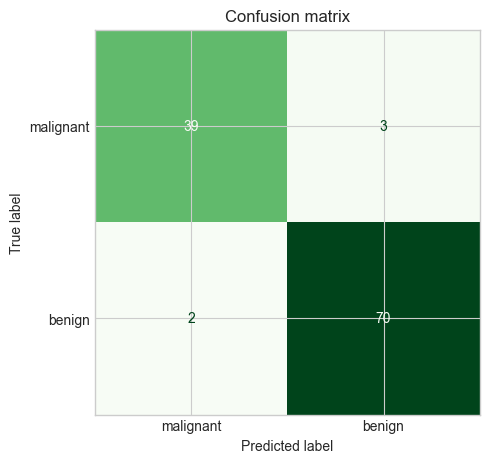

malignant called benign (missed cancer): 3
benign called malignant (false alarm):   2


In [17]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

y_pred = forest.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

print(classification_report(y_test, y_pred, target_names=["malignant", "benign"], digits=3))

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_title("Confusion matrix")
plt.show()

missed = cm[0, 1]
false_alarm = cm[1, 0]
print(f"malignant called benign (missed cancer): {missed}")
print(f"benign called malignant (false alarm):   {false_alarm}")

Three malignant samples were called benign, and two benign samples were called
malignant. The counts are similar; the **consequences** are not. A false alarm
leads to another test. A missed malignancy leads to a cancer going untreated.

Recall on the malignant class — the share of malignant cases actually caught —
is therefore the number to watch, and lesson 07's threshold argument applies
directly: `predict_proba` gives a probability, and lowering the cut-off below 0.5
would catch more malignancies at the cost of more false alarms. For this kind of
question that is usually the right trade.

**This is a teaching dataset, not a diagnostic tool.** It is 569 biopsies from
one study in the 1990s, already reduced to clean numeric measurements. Nothing
here should inform a real diagnosis.

### Reading the result

| Model | Test accuracy |
|---|---|
| Always answer "benign" | 0.632 |
| Single decision tree | 0.912 |
| Hand-built forest, 50 trees | 0.939 |
| scikit-learn forest, 100 trees | 0.956 |

The forest converts a tree that memorises its training set into a model that
generalises, and it does so without any tuning: these are the default settings.
That reliability is why random forests are a standard first thing to try on
tabular data.

What was given up in exchange is the thing lesson 06 valued most. A single tree
could be printed out and read as a prescribing rule. A hundred trees voting
cannot be read at all — feature importances are a summary of the forest, not an
explanation of any decision it makes. When a model must be auditable, that trade
may not be acceptable.

What has **not** changed is the ceiling imposed by the data. Averaging removes
variance, never bias and never noise. A forest on the wrong features still fails;
it just fails consistently.

## 7. References

- Dataset: [Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic),
  UCI Machine Learning Repository, distributed with scikit-learn as
  `sklearn.datasets.load_breast_cancer`.
- Breiman, L. (2001). *Random Forests*. Machine Learning 45(1), 5-32 - the paper
  that introduced the method and the variance argument used in section 3.
- scikit-learn documentation: [Forests of randomized trees](https://scikit-learn.org/stable/modules/ensemble.html#forest)
- Builds directly on [lesson 06 - Decision Trees](../06-decision-trees/), which
  ends by naming the weakness this lesson fixes.